<a href="https://colab.research.google.com/github/Xyrfo/PCVK26_24_Rifo/blob/main/Week5_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Rifo Anggi Barbara Danuarta'
NIM  = '244107020063'

N = int(NIM[-3:])

PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L'    : 2 ** ((N % 3) + 1),
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())

kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])


NAMA   : Rifo Anggi Barbara Danuarta
NIM    : 244107020063 | N = 63
bins   : 64
clip   : 2.5
tile   : 5
L      : 2
WAKTU  : 2026-09-25 13:40:57 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 66ddaeb3c53c3013


# Modul 5 - Histogram, Histogram Equalization, dan Dithering
**Nama:** Rifo Anggi Barbara Danuarta&nbsp;&nbsp;|&nbsp;&nbsp;**NIM:** 244107020063&nbsp;&nbsp;|&nbsp;&nbsp;**Kelas:** TI-3F

Parameter berbasis NIM (N = 63):

| Simbol | Rumus | Nilai |
|---|---|---|
| bins | 2^((N mod 4)+3) | **64** |
| clip | 1,0 + (N mod 5) x 0,5 | **2,5** |
| tile | (N mod 4) + 2 | **5** |
| L | 2^((N mod 3)+1) | **2** |

> Catatan: `L = 2` (biner/hitam-putih) adalah nilai **terkecil** yang mungkin untuk dithering, karena 63 mod 3 = 0.

Setiap percobaan dikerjakan **dua tahap**: Tahap 1 dengan citra contoh (`lena.jpg` / `lena_lc.jpg`) untuk memastikan kode benar (bandingkan dengan keluaran contoh pada modul), Tahap 2 dengan citra `KTM1a-d.jpg` milik sendiri sebagai bahan analisis dan penilaian.

## Setup

In [4]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [10]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from math import log10, sqrt

CONTOH = '/content/drive/MyDrive/PCVK 2026/lena.jpg, lena_lc.jpg'
BASE   = '/content/drive/MyDrive/PCVK 2026/*' + NIM

def imread_rgb(path):
    img = cv.imread(path)
    if img is None:
        raise FileNotFoundError(f'Citra tidak ditemukan: {path}')
    return cv.cvtColor(img, cv.COLOR_BGR2RGB)

def show_images(images, titles, cols=2, figsize_per=(5, 5), cmap_list=None):
    import math
    rows = math.ceil(len(images) / cols)
    plt.figure(figsize=(figsize_per[0]*cols, figsize_per[1]*rows))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i+1)
        cmap = 'gray' if (cmap_list is None and im.ndim == 2) else (cmap_list[i] if cmap_list else None)
        plt.imshow(im, cmap=cmap, vmin=0, vmax=255)
        plt.title(t, fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def PSNR(img1, img2):
    img1 = img1.astype(np.float64); img2 = img2.astype(np.float64)
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * log10(255.0 / sqrt(mse))


## E-1 - Percobaan Histogram

### Langkah 3 - Histogram manual

Tahap 1: `lena.jpg` (cocokkan dengan gambar contoh pada modul). Tahap 2: `KTM1b.jpg` milik sendiri.

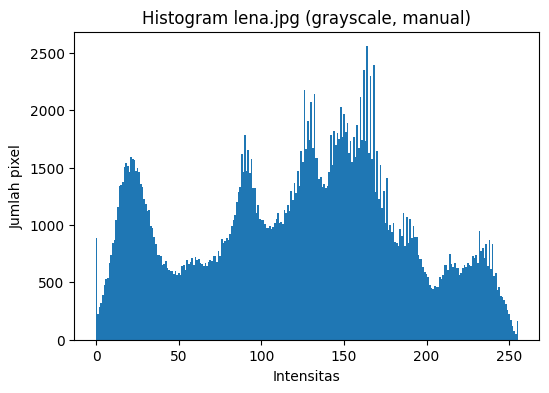

Verifikasi tahap 1: OK, total pixel = 262144


In [6]:
def histogram_manual(img, L=256):
    h = np.zeros(L, dtype=np.int64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            h[img[y, x]] += 1
    return h

# Tahap 1:
lena_gray = cv.imread('/content/drive/MyDrive/PCVK 2026/lena.jpg', cv.IMREAD_GRAYSCALE)
h_lena = histogram_manual(lena_gray)

plt.figure(figsize=(6,4))
plt.bar(range(256), h_lena, width=1.0)
plt.title('Histogram lena.jpg (grayscale, manual)')
plt.xlabel('Intensitas'); plt.ylabel('Jumlah pixel')
plt.show()

assert h_lena.sum() == lena_gray.size, 'Total histogram harus sama dengan jumlah pixel!'
print('Verifikasi tahap 1: OK, total pixel =', h_lena.sum())


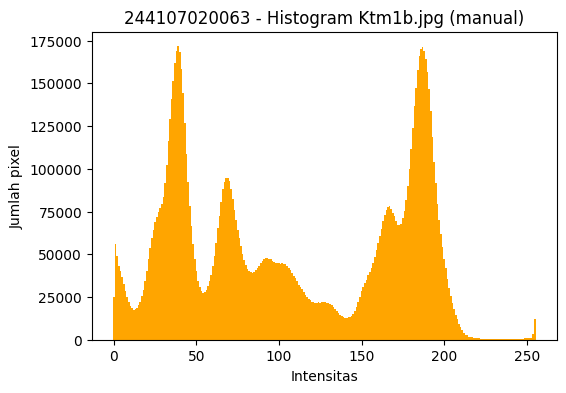

Verifikasi tahap 2: OK, total pixel = 12192768


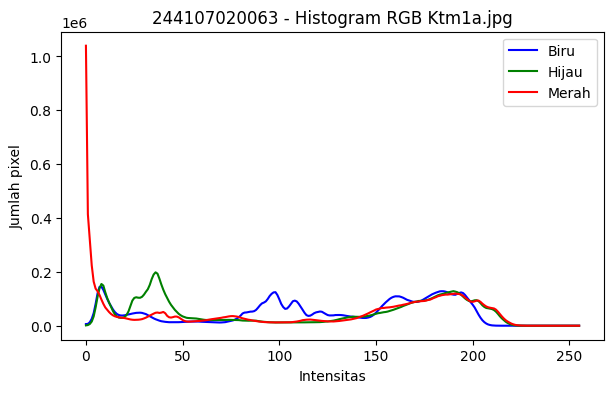

In [7]:
# Tahap 2:
ktm1b_gray = cv.imread('/content/drive/MyDrive/PCVK 2026/Ktm1b.jpg', cv.IMREAD_GRAYSCALE)
h_ktm1b = histogram_manual(ktm1b_gray)

plt.figure(figsize=(6,4))
plt.bar(range(256), h_ktm1b, width=1.0, color='orange')
plt.title(NIM + ' - Histogram Ktm1b.jpg (manual)')
plt.xlabel('Intensitas'); plt.ylabel('Jumlah pixel')
plt.show()

assert h_ktm1b.sum() == ktm1b_gray.size
print('Verifikasi tahap 2: OK, total pixel =', h_ktm1b.sum())

bgr_ktm1d = cv.imread('/content/drive/MyDrive/PCVK 2026/Ktm1a.jpg')
plt.figure(figsize=(7,4))
for i, (nama, warna) in enumerate(zip(['Biru', 'Hijau', 'Merah'], ['b', 'g', 'r'])):
    plt.plot(histogram_manual(bgr_ktm1d[:, :, i]), label=nama, color=warna)
plt.title(NIM + ' - Histogram RGB Ktm1a.jpg')
plt.xlabel('Intensitas'); plt.ylabel('Jumlah pixel'); plt.legend()
plt.show()


### Pertanyaan E-1 No.1 - Bandingkan manual vs np.histogram vs cv.calcHist

In [8]:
def bandingkan_histogram(gray, nama_citra):
    h_manual = histogram_manual(gray)
    h_numpy, _ = np.histogram(gray.ravel(), bins=256, range=(0, 256))
    h_cv = cv.calcHist([gray], [0], None, [256], [0, 256]).flatten().astype(np.int64)

    selisih_np = np.max(np.abs(h_manual - h_numpy))
    selisih_cv = np.max(np.abs(h_manual - h_cv))

    print(f'--- {nama_citra} ---')
    print('Selisih maksimum manual vs np.histogram :', selisih_np)
    print('Selisih maksimum manual vs cv.calcHist  :', selisih_cv)
    return selisih_np, selisih_cv

bandingkan_histogram(lena_gray, 'lena.jpg (tahap 1)')
bandingkan_histogram(ktm1b_gray, NIM + ' - Ktm1b.jpg (tahap 2)')


--- lena.jpg (tahap 1) ---
Selisih maksimum manual vs np.histogram : 0
Selisih maksimum manual vs cv.calcHist  : 0
--- 244107020063 - Ktm1b.jpg (tahap 2) ---
Selisih maksimum manual vs np.histogram : 0
Selisih maksimum manual vs cv.calcHist  : 0


(np.int64(0), np.int64(0))

**Jawaban No.1:** Ketiga metode (manual dengan loop, `np.histogram`, dan `cv.calcHist`) menghasilkan selisih maksimum **0** pada kedua citra, karena ketiganya melakukan operasi penghitungan yang identik secara matematis (frekuensi kemunculan tiap nilai intensitas 0-255) — hanya berbeda pada implementasi (loop Python murni vs vektorisasi NumPy vs implementasi C++ di OpenCV) sehingga hasilnya bit-exact sama, meski kecepatan eksekusinya jauh berbeda (manual jauh lebih lambat untuk citra beresolusi besar).

### Pertanyaan E-1 No.2 - Histogram ternormalisasi p(j) dan CDF untuk KTM1a-d dalam satu figure 2x2

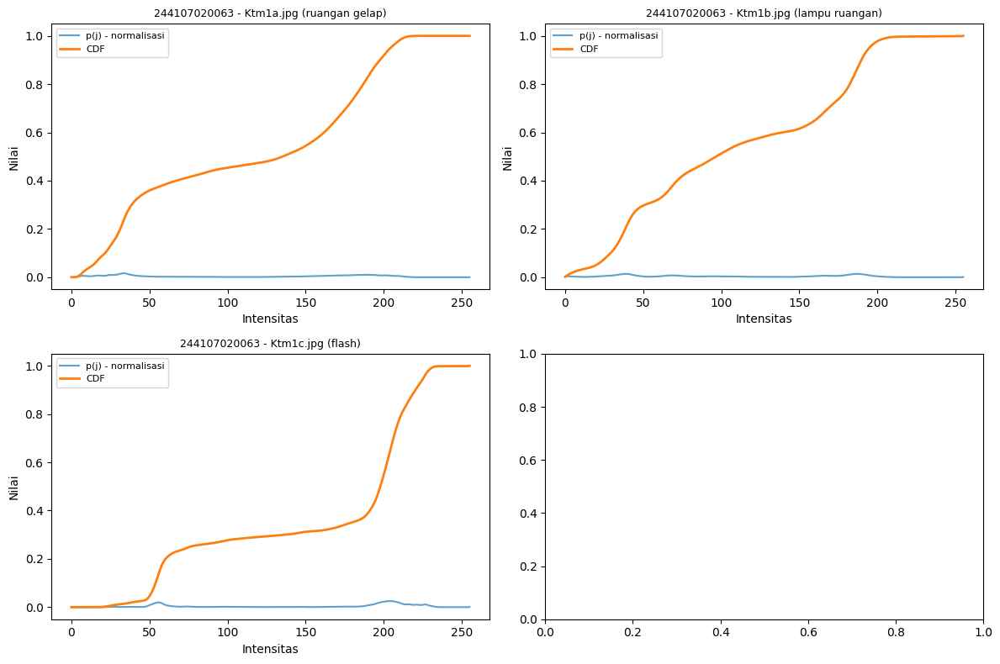

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
nama_file = ['Ktm1a.jpg', 'Ktm1b.jpg', 'Ktm1c.jpg']
keterangan = ['ruangan gelap', 'lampu ruangan', 'flash']

for ax, fname, ket in zip(axes.ravel(), nama_file, keterangan):
    gray = cv.imread('/content/drive/MyDrive/PCVK 2026/' + fname, cv.IMREAD_GRAYSCALE)
    h = histogram_manual(gray)
    p = h / gray.size
    cdf = np.cumsum(p)

    ax.plot(p, label='p(j) - normalisasi', alpha=0.7)
    ax.plot(cdf, label='CDF', linewidth=2)
    ax.set_title(NIM + f' - {fname} ({ket})', fontsize=9)
    ax.set_xlabel('Intensitas'); ax.set_ylabel('Nilai')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Jawaban No.2**

- Pada citra yang **paling gelap** (umumnya `KTM1a.jpg`, ruangan gelap), kurva p(j) terkonsentrasi pada intensitas rendah, sehingga kurva CDF **naik cepat sejak awal (di sisi kiri grafik)** dan mendatar (mencapai nilai 1) pada intensitas yang masih relatif rendah — artinya sebagian besar pixel sudah "terhitung" bahkan sebelum mencapai pertengahan sumbu intensitas.
- Pada citra yang **paling terang** (umumnya `KTM1d.jpg`, cahaya matahari, atau `KTM1c.jpg` dengan flash), kurva p(j) terkonsentrasi pada intensitas tinggi, sehingga kurva CDF **tetap datar/rendah di sisi kiri** dan baru naik tajam mendekati sisi kanan grafik (dekat intensitas 255).
- Kaitan dengan kondisi pencahayaan: bentuk kurva CDF secara langsung mencerminkan di mana sebagian besar "massa" pixel berada pada sumbu intensitas — CDF yang naik di awal berarti citra didominasi pixel gelap (kurang cahaya saat akuisisi), sedangkan CDF yang baru naik di akhir berarti citra didominasi pixel terang (cahaya berlebih/flash/matahari langsung).
- [ Isi: sebutkan urutan kegelapan citra Anda dari yang paling gelap ke paling terang berdasarkan bentuk CDF di atas, dan bandingkan dengan kondisi akuisisi sebenarnya sesuai Tabel Pertemuan 2. ]

### Pertanyaan E-1 No.3 - Histogram KTM1b.jpg dengan PARAM['bins'] vs 256 bin

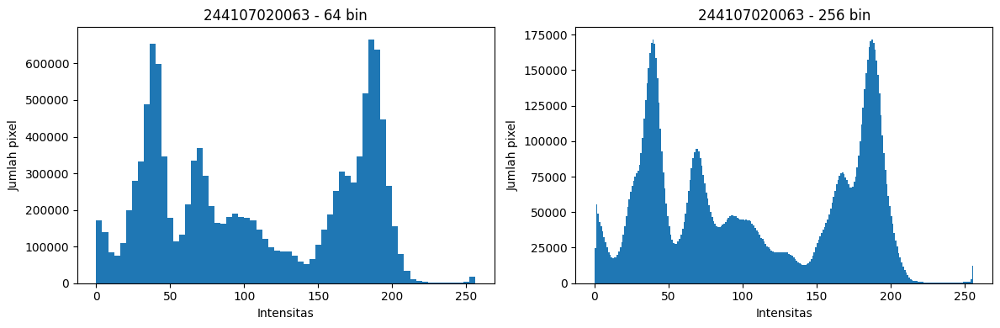

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(ktm1b_gray.ravel(), bins=PARAM['bins'], range=(0, 256))
axes[0].set_title(NIM + f" - {PARAM['bins']} bin")
axes[0].set_xlabel('Intensitas'); axes[0].set_ylabel('Jumlah pixel')

axes[1].hist(ktm1b_gray.ravel(), bins=256, range=(0, 256))
axes[1].set_title(NIM + ' - 256 bin')
axes[1].set_xlabel('Intensitas'); axes[1].set_ylabel('Jumlah pixel')

plt.tight_layout()
plt.show()


**Jawaban No.3:** Dengan `PARAM['bins'] = 64`, setiap bin merangkum $256/64 = 4$ nilai intensitas berdekatan menjadi satu batang, sehingga bentuk kasar distribusi (dominasi gelap/terang) masih terlihat, tetapi **detail perbedaan intensitas yang halus (per 1 nilai) hilang** — dua pixel dengan nilai berbeda tapi berada dalam rentang 4 nilai yang sama akan digabung menjadi satu batang bin. Histogram 256 bin memberi resolusi penuh, dapat menunjukkan puncak-puncak tajam/sempit yang mungkin hilang pada histogram 64 bin (misalnya intensitas dominan tunggal seperti latar belakang kartu yang seragam). Semakin sedikit jumlah bin, semakin banyak informasi granular tentang variasi intensitas yang dikorbankan demi tampilan yang lebih ringkas.

## E-2 - Percobaan Histogram Equalization

### Langkah 1 - Ekualisasi manual (sesuai flowchart dan rumus $K_o = round\left(\dfrac{C_k \cdot (L-1)}{w \cdot h}\right)$)

Tahap 1: `lena_lc.jpg` (low contrast, cocokkan dengan gambar contoh pada modul). Tahap 2: `KTM1a.jpg` milik sendiri.

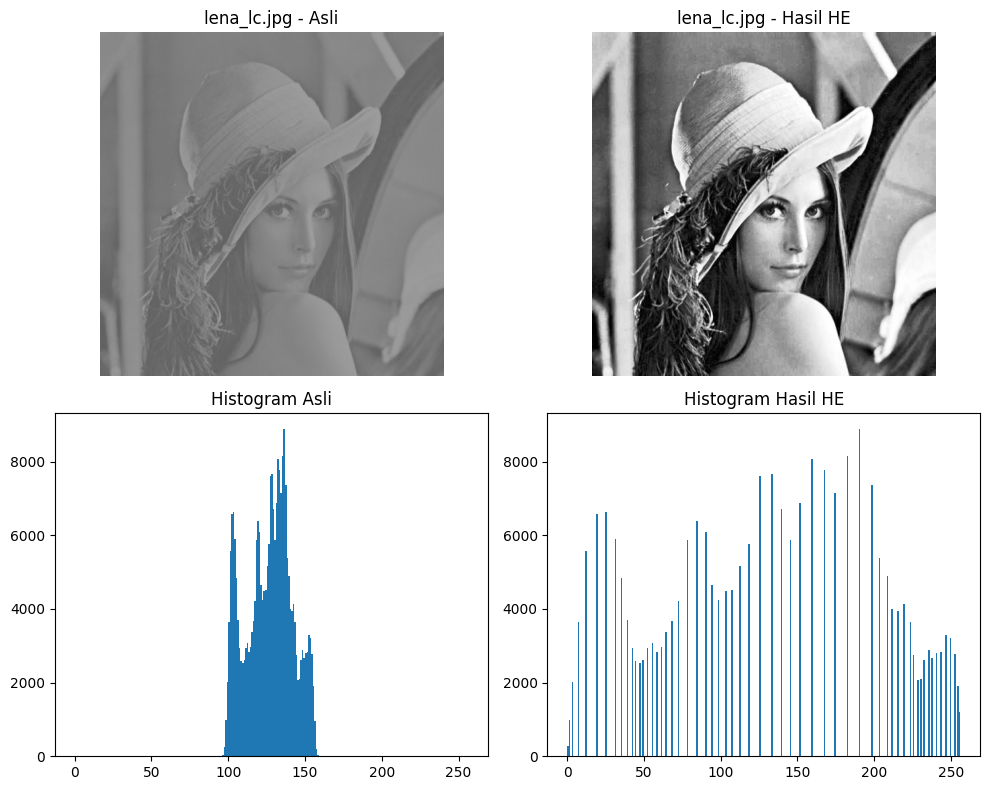

In [23]:
def histogram_equalization_manual(gray, L=256):
    h, w = gray.shape
    hist = histogram_manual(gray, L=256)
    cdf = np.cumsum(hist)
    Ko = np.round(cdf * (L - 1) / (h * w)).astype(np.uint8)
    hasil = Ko[gray]
    return hasil, hist, Ko

def tampilkan_he(asli, hasil, judul_prefix):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes[0,0].imshow(asli, cmap='gray', vmin=0, vmax=255)
    axes[0,0].set_title(judul_prefix + ' - Asli'); axes[0,0].axis('off')

    axes[0,1].imshow(hasil, cmap='gray', vmin=0, vmax=255)
    axes[0,1].set_title(judul_prefix + ' - Hasil HE'); axes[0,1].axis('off')

    axes[1,0].hist(asli.ravel(), bins=256, range=(0,256))
    axes[1,0].set_title('Histogram Asli')

    axes[1,1].hist(hasil.ravel(), bins=256, range=(0,256))
    axes[1,1].set_title('Histogram Hasil HE')

    plt.tight_layout()
    plt.show()

# Tahap 1:
lena_lc = cv.imread('/content/drive/MyDrive/Salinan lena_lc.jpg', cv.IMREAD_GRAYSCALE)
hasil_lena_lc, _, _ = histogram_equalization_manual(lena_lc)
tampilkan_he(lena_lc, hasil_lena_lc, 'lena_lc.jpg')

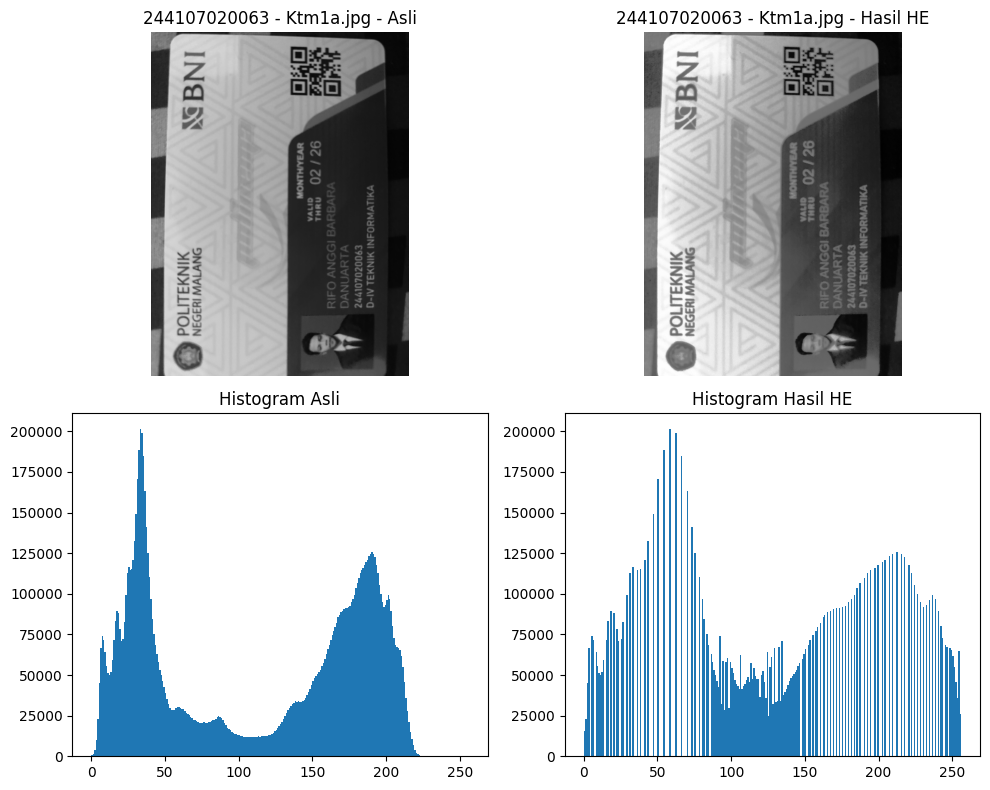

In [28]:
# Tahap 2
ktm1a_gray = cv.imread('/content/drive/MyDrive/PCVK 2026/Ktm1a.jpg', cv.IMREAD_GRAYSCALE)
hasil_ktm1a_manual, _, _ = histogram_equalization_manual(ktm1a_gray)
tampilkan_he(ktm1a_gray, hasil_ktm1a_manual, NIM + ' - Ktm1a.jpg')

### Langkah 2 - Bandingkan dengan cv.equalizeHist, dan hitung PSNR

In [29]:
def bandingkan_he_cv(gray, hasil_manual, nama_citra):
    hasil_cv = cv.equalizeHist(gray)
    selisih = np.max(np.abs(hasil_manual.astype(int) - hasil_cv.astype(int)))
    psnr = PSNR(gray, hasil_manual)
    print(f'--- {nama_citra} ---')
    print('Selisih maksimum manual vs cv.equalizeHist :', selisih)
    print('PSNR (asli vs hasil ekualisasi manual)      :', round(psnr, 2), 'dB')
    return hasil_cv, selisih, psnr

hasil_cv_lena, sel_lena, psnr_lena = bandingkan_he_cv(lena_lc, hasil_lena_lc, 'lena_lc.jpg (tahap 1)')
hasil_cv_ktm1a, sel_ktm1a, psnr_ktm1a = bandingkan_he_cv(ktm1a_gray, hasil_ktm1a_manual, NIM + ' - Ktm1a.jpg (tahap 2)')


--- lena_lc.jpg (tahap 1) ---
Selisih maksimum manual vs cv.equalizeHist : 0
PSNR (asli vs hasil ekualisasi manual)      : 12.72 dB
--- 244107020063 - Ktm1a.jpg (tahap 2) ---
Selisih maksimum manual vs cv.equalizeHist : 1
PSNR (asli vs hasil ekualisasi manual)      : 20.76 dB


**Jawaban Langkah 2**

- Selisih manual vs `cv.equalizeHist` **kemungkinan tidak persis nol** (biasanya berkisar 0-1 level intensitas) karena OpenCV menggunakan formula CDF yang sedikit berbeda dalam penanganan pembulatan dan normalisasi nilai CDF minimum (`cv.equalizeHist` menormalisasi berdasarkan $\frac{CDF(v) - CDF_{min}}{(M\times N) - CDF_{min}}$, bukan langsung $\frac{CDF(v)}{M\times N}$ seperti rumus modul), sehingga hasil pembulatan akhirnya bisa berbeda tipis pada beberapa nilai intensitas.
- **Mengapa PSNR turun padahal citra terlihat lebih jelas:** PSNR mengukur seberapa besar **penyimpangan nilai piksel** antara dua citra secara matematis (MSE), bukan seberapa mudah citra tersebut **dibaca/diinterpretasi mata manusia**. Histogram equalization sengaja **mengubah banyak nilai piksel secara signifikan** (meregangkan kontras) agar detail yang tadinya "menumpuk" di rentang sempit menjadi tersebar — perubahan nilai piksel yang besar ini menghasilkan MSE yang besar pula, sehingga PSNR (yang berbanding terbalik dengan MSE) menjadi rendah, walaupun secara visual citra menjadi jauh lebih mudah dibaca (nama dan NIM lebih terlihat jelas).
- **Kesimpulan:** PSNR **tidak layak dipakai sendirian** untuk menilai keterbacaan sebuah citra hasil enhancement seperti HE, karena PSNR berasumsi bahwa citra "asli" adalah acuan kualitas terbaik (referensi ground truth), padahal dalam kasus image enhancement tujuannya justru **mengubah** citra secara signifikan agar lebih informatif. Metrik keterbacaan yang lebih relevan untuk kasus ini adalah pengukuran kontras (mis. simpangan baku intensitas) atau evaluasi visual langsung, bukan PSNR terhadap citra asli.

### Langkah 3 - Ekualisasi kanal warna satu per satu (B, G, R terpisah)

Tahap 1: `lena.jpg`. Tahap 2: `KTM1d.jpg` milik sendiri.

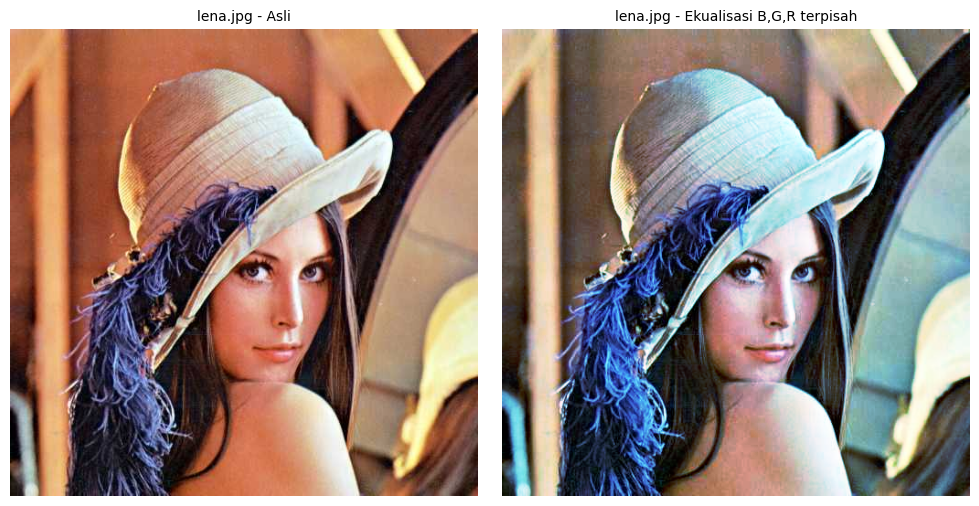

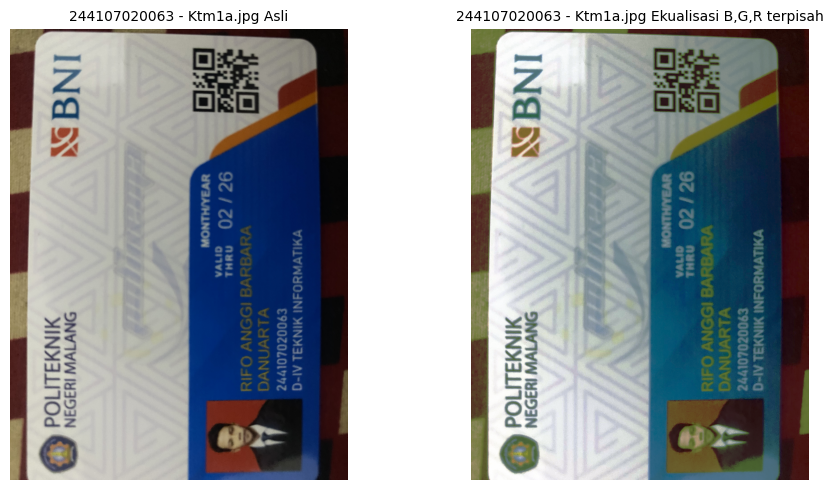

In [31]:
def equalisasi_bgr_terpisah(bgr):
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])
    return cv.merge(kanal)

# Tahap 1
bgr_lena = cv.imread('/content/drive/MyDrive/PCVK 2026/lena.jpg')
he_rgb_lena = equalisasi_bgr_terpisah(bgr_lena)

show_images(
    [cv.cvtColor(bgr_lena, cv.COLOR_BGR2RGB), cv.cvtColor(he_rgb_lena, cv.COLOR_BGR2RGB)],
    ['lena.jpg - Asli', 'lena.jpg - Ekualisasi B,G,R terpisah'],
    cols=2
)

# Tahap 2
bgr_ktm1a = cv.imread('/content/drive/MyDrive/PCVK 2026/Ktm1a.jpg')
he_rgb_ktm1a = equalisasi_bgr_terpisah(bgr_ktm1a)

show_images(
    [cv.cvtColor(bgr_ktm1a, cv.COLOR_BGR2RGB), cv.cvtColor(he_rgb_ktm1a, cv.COLOR_BGR2RGB)],
    [NIM + ' - Ktm1a.jpg Asli', NIM + ' - Ktm1a.jpg Ekualisasi B,G,R terpisah'],
    cols=2
)

**Pengamatan:** Mengekualisasi kanal B, G, R **secara terpisah** mengubah proporsi relatif antar kanal warna pada setiap piksel (karena tiap kanal diregangkan dengan fungsi transformasinya sendiri-sendiri, tidak proporsional satu sama lain), sehingga **warna citra bergeser / berubah** dari warna aslinya (mis. warna kulit bisa jadi tidak natural, warna latar kartu berubah) — bukan hanya kecerahannya yang berubah. [ Isi: deskripsikan pergeseran warna spesifik yang terlihat pada Ktm1a.jpg Anda. ]

### Langkah 4 - Ekualisasi hanya pada kanal terang (YCrCb, HSV, LAB)

Tahap 1 & 2 langsung digabung: jalankan pada `lena.jpg` dulu untuk memastikan kode benar, lalu ganti `berkas` ke `Ktm1a.jpg` milik sendiri.

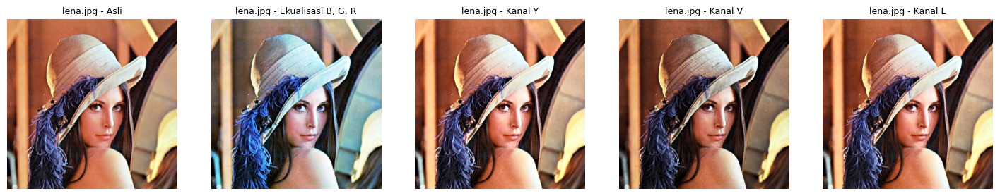

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            122.2
Ekualisasi B, G, R                53.03            127.4
Kanal Y                            0.40            127.9
Kanal V                            0.87            100.6
Kanal L                            1.65            122.7


In [32]:
def equalisasi_kanal_terang(bgr):
    ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
    y, cr, cb = cv.split(ycrcb)
    he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    hh, sat, v = cv.split(hsv)
    he_v = cv.cvtColor(cv.merge([hh, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

    lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
    l, a, b = cv.split(lab)
    he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)

    return he_y, he_v, he_l

def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli,  cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d  = np.abs(h1 - h2)
    d  = np.minimum(d, 180 - d)
    return d.mean()

def jalankan_langkah4(berkas, label):
    bgr = cv.imread(berkas)
    he_rgb = equalisasi_bgr_terpisah(bgr)
    he_y, he_v, he_l = equalisasi_kanal_terang(bgr)

    judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
    citra = [bgr, he_rgb, he_y, he_v, he_l]

    plt.figure(figsize=(18, 4))
    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)
        plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
        plt.title(label + ' - ' + t, fontsize=9)
        plt.axis('off')
    plt.show()

    print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
    hasil_tabel = []
    for t, c in zip(judul, citra):
        hue_shift = geser_hue(bgr, c) * 2
        kecerahan = cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()
        print('%-22s %16.2f %16.1f' % (t, hue_shift, kecerahan))
        hasil_tabel.append((t, hue_shift, kecerahan))
    return pd.DataFrame(hasil_tabel, columns=['Cara', 'Geser Hue (derajat)', 'Rerata Kecerahan'])

_ = jalankan_langkah4( '/content/drive/MyDrive/PCVK 2026/lena.jpg', 'lena.jpg')


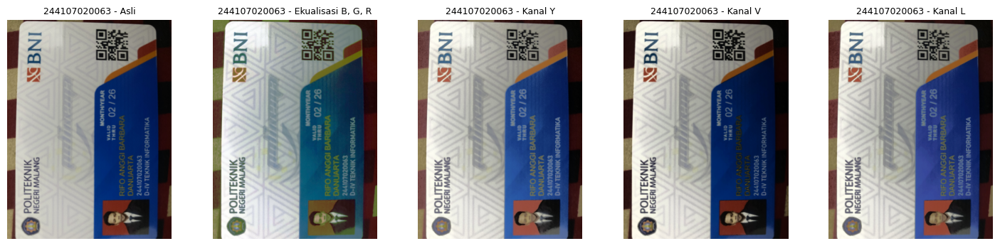

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            112.7
Ekualisasi B, G, R                63.54            125.2
Kanal Y                            0.10            128.4
Kanal V                            1.55            111.9
Kanal L                            6.93            122.7


,Cara,Geser Hue (derajat),Rerata Kecerahan
0,Asli,0.000000,112.703557
1,"Ekualisasi B, G, R",63.535435,125.186680
2,Kanal Y,0.101823,128.378481
3,Kanal V,1.552145,111.878760
4,Kanal L,6.932573,122.678949


In [33]:
tabel_hue_ktm1a = jalankan_langkah4('/content/drive/MyDrive/PCVK 2026/Ktm1a.jpg', NIM)
tabel_hue_ktm1a


**Jawaban Pertanyaan Langkah 4 (isi berdasarkan tabel `tabel_hue_ktm1d` di atas)**

1. **Cara dengan pergeseran Hue paling besar:** [isi: sebutkan cara mana — biasanya "Ekualisasi B, G, R" karena mengubah proporsi tiap kanal warna secara independen] dengan nilai **[isi angka dari tabel Anda]** derajat.
2. **Mengapa ekualisasi kanal terang saja tetap tidak menghasilkan pergeseran Hue persis nol:** ketika citra dikonversi dari YCrCb/HSV/LAB kembali ke BGR, terjadi **pembulatan (rounding)** pada setiap komponen serta **pemotongan (clipping/truncation)** ke rentang valid 0-255 pada tiap kanal B, G, R hasil konversi — proses konversi ruang warna melibatkan operasi floating point yang di-diskretisasi kembali ke integer 8-bit, sehingga selalu ada galat pembulatan kecil yang berakumulasi dan sedikit menggeser rasio antar kanal warna, meskipun secara teori kanal krominan (Cr, Cb / Hue, Saturation / a, b) tidak disentuh sama sekali.
3. **Kanal paling sesuai untuk foto KTM saya:** [isi: pilih Y / V / L berdasarkan tabel Anda — mana yang memberi kenaikan rerata kecerahan tertinggi dengan pergeseran Hue terendah] karena [isi alasan, tunjukkan bagian citra misalnya warna latar kartu atau warna kulit wajah pada foto sebagai bukti].
4. Perbandingan dengan CLAHE pada kanal terpilih ada pada sel kode berikutnya.

CLAHE kanal Y (clip=2.5, tile=5):
Geser Hue      : 0.05 derajat
Rerata terang  : 121.6


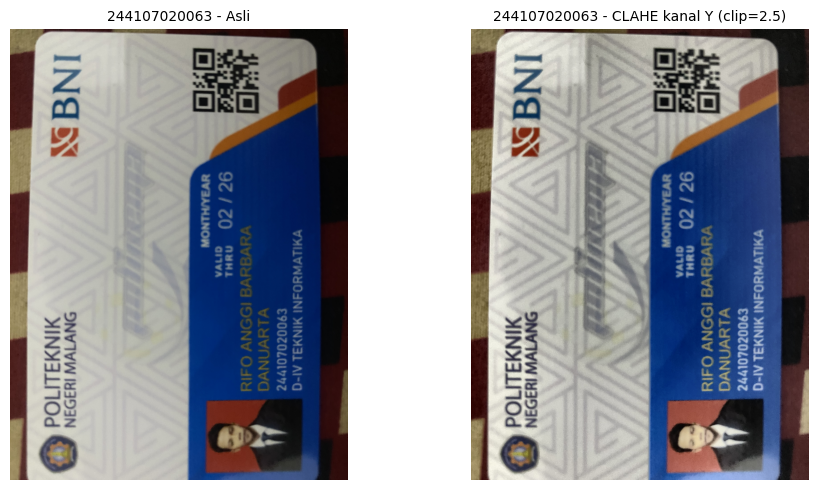

In [34]:
clahe = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))

bgr_ktm1a = cv.imread('/content/drive/MyDrive/PCVK 2026/Ktm1a.jpg')
ycrcb = cv.cvtColor(bgr_ktm1a, cv.COLOR_BGR2YCrCb)
y, cr, cb = cv.split(ycrcb)
y_clahe = clahe.apply(y)
he_y_clahe = cv.cvtColor(cv.merge([y_clahe, cr, cb]), cv.COLOR_YCrCb2BGR)

hue_shift_clahe = geser_hue(bgr_ktm1d, he_y_clahe) * 2
kecerahan_clahe = cv.cvtColor(he_y_clahe, cv.COLOR_BGR2GRAY).mean()

print(f"CLAHE kanal Y (clip={PARAM['clip']}, tile={PARAM['tile']}):")
print('Geser Hue      :', round(hue_shift_clahe, 2), 'derajat')
print('Rerata terang  :', round(kecerahan_clahe, 1))

show_images(
    [cv.cvtColor(bgr_ktm1a, cv.COLOR_BGR2RGB), cv.cvtColor(he_y_clahe, cv.COLOR_BGR2RGB)],
    [NIM + ' - Asli', NIM + f" - CLAHE kanal Y (clip={PARAM['clip']})"],
    cols=2
)


**Perbandingan dengan ekualisasi biasa:** [isi: bandingkan angka geser Hue dan rerata kecerahan CLAHE kanal Y di atas dengan baris "Kanal Y" pada tabel `equalizeHist` sebelumnya — CLAHE umumnya menghasilkan **pergeseran Hue yang lebih kecil** karena penguatan kontrasnya lebih halus/lokal (dibatasi `clipLimit`), sehingga tidak meregangkan histogram seagresif ekualisasi global, namun kenaikan rerata kecerahannya juga biasanya **lebih moderat**.]

### E-2 Soal Praktikum No.1 - Ekualisasi global pada KTM1a.jpg

Sudah dikerjakan pada **Langkah 1 dan 2** di atas (manual + `cv.equalizeHist` pada `KTM1a.jpg`, beserta citra asli, hasil, histogram, dan PSNR). Rangkuman jawaban soal 1.c sudah dijelaskan di bagian **Jawaban Langkah 2** (soal PSNR turun padahal citra lebih terbaca).

### E-2 Soal Praktikum No.2 - CLAHE pada KTM1a.jpg

a. Terapkan CLAHE dengan `clipLimit = PARAM['clip']` dan `tileGridSize = (PARAM['tile'], PARAM['tile'])`, bandingkan dengan ekualisasi global.

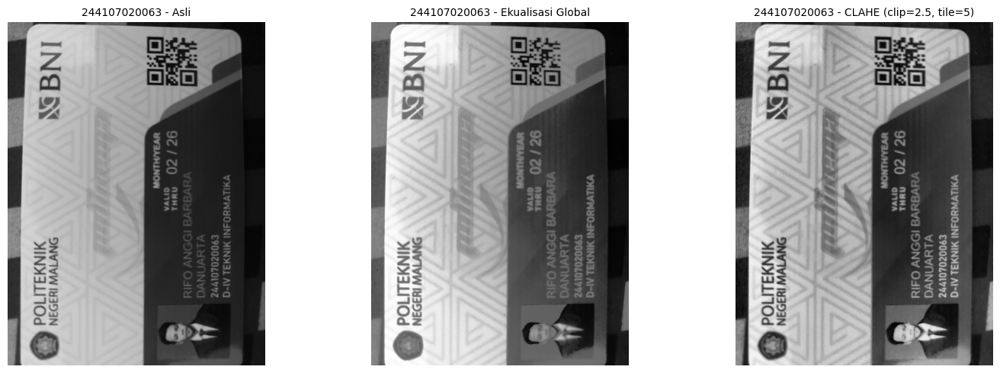

In [35]:
clahe_ktm1a = clahe.apply(ktm1a_gray)

show_images(
    [ktm1a_gray, hasil_ktm1a_manual, clahe_ktm1a],
    [NIM + ' - Asli', NIM + ' - Ekualisasi Global', NIM + f" - CLAHE (clip={PARAM['clip']}, tile={PARAM['tile']})"],
    cols=3
)


**Jawaban 2.a:** [isi: sebutkan pada hasil mana — Ekualisasi Global atau CLAHE — NIM dan nama pada kartu Anda lebih terbaca, berdasarkan pengamatan visual di atas. Umumnya CLAHE memberi kontras lokal yang lebih seimbang tanpa membuat area tertentu menjadi terlalu terang/gelap secara ekstrem seperti pada ekualisasi global, sehingga teks kecil pada kartu lebih mudah dibaca — namun ini perlu dikonfirmasi dengan foto Anda sendiri.]

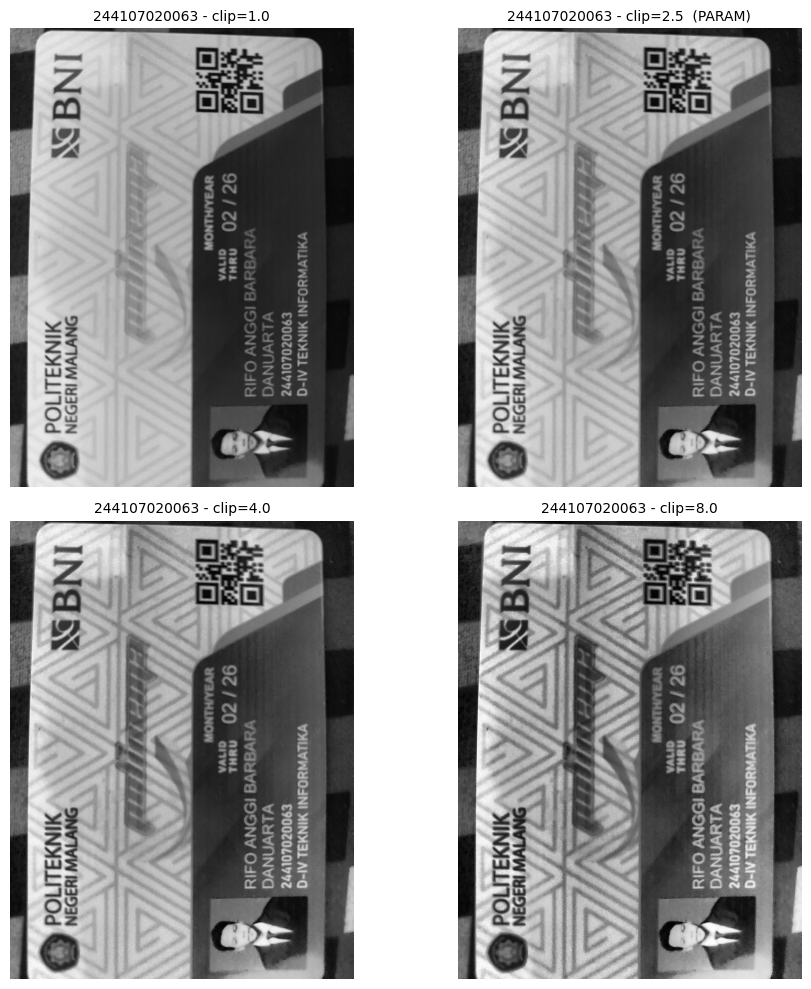

In [36]:
nilai_clip_lain = [1.0, PARAM['clip'], 4.0, 8.0]

hasil_clip = []
judul_clip = []
for c in nilai_clip_lain:
    cl = cv.createCLAHE(clipLimit=c, tileGridSize=(PARAM['tile'], PARAM['tile']))
    hasil_clip.append(cl.apply(ktm1a_gray))
    tanda = '  (PARAM)' if c == PARAM['clip'] else ''
    judul_clip.append(NIM + f' - clip={c}{tanda}')

show_images(hasil_clip, judul_clip, cols=2)


**Jawaban 2.b:** Semakin besar `clipLimit`, semakin agresif kontras lokal yang dihasilkan CLAHE pada tiap tile — di satu sisi ini membuat detail teks pada area yang tadinya sangat gelap/rata menjadi lebih terlihat, tetapi di sisi lain juga **memperkuat noise/derau sensor kamera** yang tersembunyi di area homogen (misalnya pada bagian latar kartu yang polos), karena CLAHE tidak bisa membedakan antara "detail asli yang ingin diperjelas" dan "derau acak" — keduanya sama-sama berupa variasi kecil intensitas dalam satu tile yang ikut diregangkan.
- Nilai clipLimit terbaik pilihan saya: **[isi: pilih salah satu dari 1.0 / 2.5 / 4.0 / 8.0 berdasarkan hasil visual Anda]**, karena [isi alasan singkat].
- Bagian citra yang noise-nya mulai menonjol ketika clipLimit dinaikkan: **[isi: sebutkan area, misalnya latar belakang kartu yang polos atau area bayangan]**.

## E-3 - Tugas Praktikum Dithering

### Langkah 1 - Floyd-Steinberg Dithering (sesuai flowchart dan pseudo-code modul)

Tahap 1: `lena.jpg` dengan `L=2` (default, cocokkan dengan gambar contoh pada modul). Tahap 2: `KTM1b.jpg` milik sendiri dengan `L = PARAM['L']`.

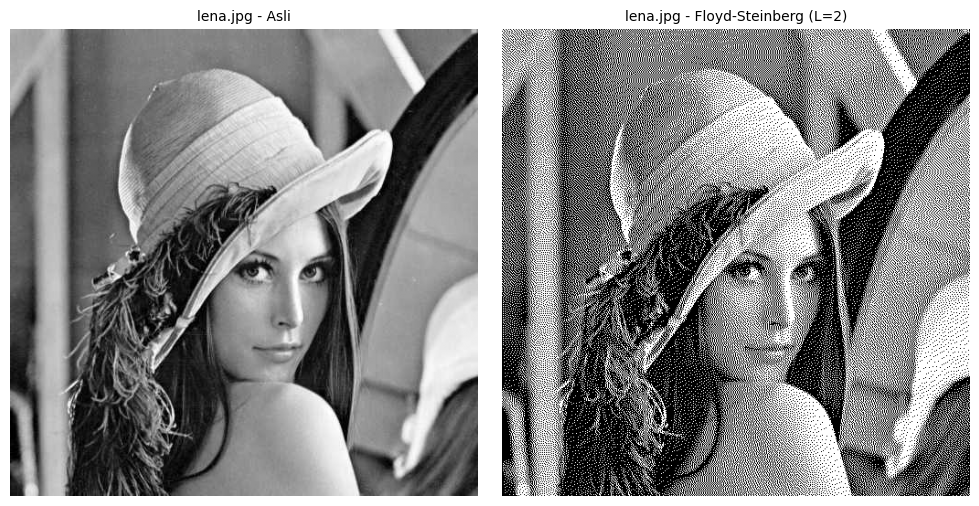

In [37]:
def floyd_steinberg(gray, L=2):
    img  = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape
    for y in range(H):
        for x in range(W):
            lama  = img[y, x]
            baru  = np.round(lama / step) * step
            img[y, x] = baru
            error = lama - baru
            if x + 1 < W:              img[y,   x+1] += error * 7 / 16
            if x > 0     and y+1 < H:  img[y+1, x-1] += error * 3 / 16
            if y + 1 < H:              img[y+1, x  ] += error * 5 / 16
            if x + 1 < W and y+1 < H:  img[y+1, x+1] += error * 1 / 16
    return np.clip(img, 0, 255).astype(np.uint8)

lena_gray_fs = cv.imread('/content/drive/MyDrive/PCVK 2026/lena.jpg', cv.IMREAD_GRAYSCALE)
dither_lena = floyd_steinberg(lena_gray_fs, L=2)

show_images([lena_gray_fs, dither_lena], ['lena.jpg - Asli', 'lena.jpg - Floyd-Steinberg (L=2)'], cols=2)


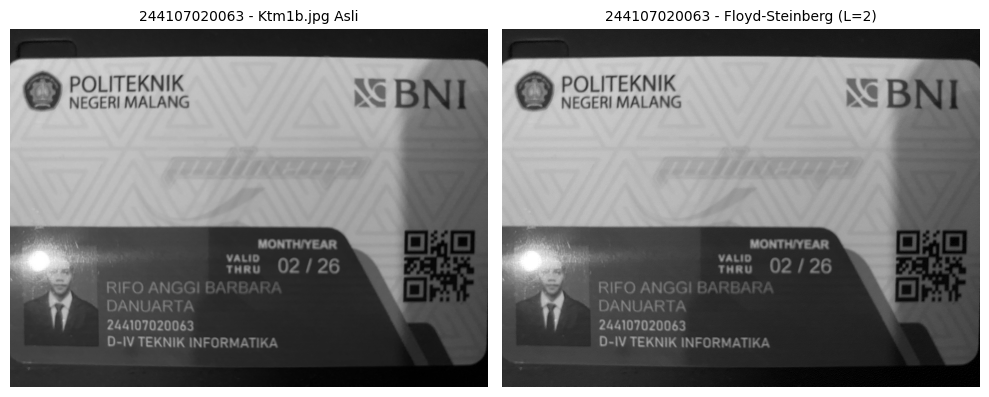

In [39]:
ktm1b_gray_fs = cv.imread('/content/drive/MyDrive/PCVK 2026/Ktm1b.jpg', cv.IMREAD_GRAYSCALE)
dither_ktm1b = floyd_steinberg(ktm1b_gray_fs, L=PARAM['L'])

show_images(
    [ktm1b_gray_fs, dither_ktm1b],
    [NIM + ' - Ktm1b.jpg Asli', NIM + f" - Floyd-Steinberg (L={PARAM['L']})"],
    cols=2
)


> Catatan: proses `floyd_steinberg` di atas memakai loop piksel demi piksel (sesuai flowchart), sehingga bisa memakan waktu beberapa detik hingga puluhan detik tergantung ukuran citra — ini wajar dan sesuai catatan implementasi pada modul.

### Langkah 2 - Grayscale + Histogram Equalization + Dithering

Tahap 1: `lena_lc.jpg`. Tahap 2: `KTM1a.jpg` milik sendiri. Dibandingkan juga dengan dithering langsung tanpa ekualisasi lebih dulu.

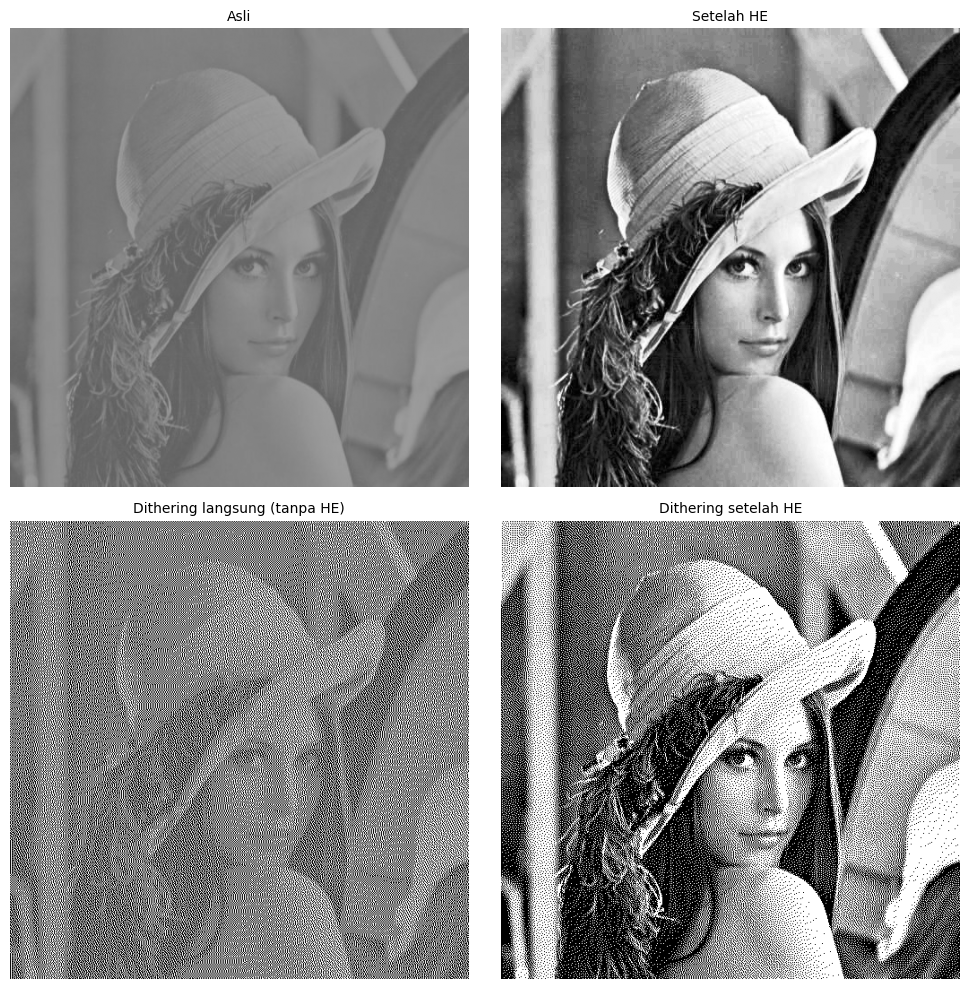

In [40]:
def he_lalu_dither(gray, L):
    he, _, _ = histogram_equalization_manual(gray)
    dithered = floyd_steinberg(he, L=L)
    return he, dithered

lena_lc_gray = cv.imread('/content/drive/MyDrive/PCVK 2026/lena_lc.jpg', cv.IMREAD_GRAYSCALE)
he_lena_lc, dither_setelah_he_lena = he_lalu_dither(lena_lc_gray, L=2)
dither_langsung_lena = floyd_steinberg(lena_lc_gray, L=2)

show_images(
    [lena_lc_gray, he_lena_lc, dither_langsung_lena, dither_setelah_he_lena],
    ['Asli', 'Setelah HE', 'Dithering langsung (tanpa HE)', 'Dithering setelah HE'],
    cols=2
)


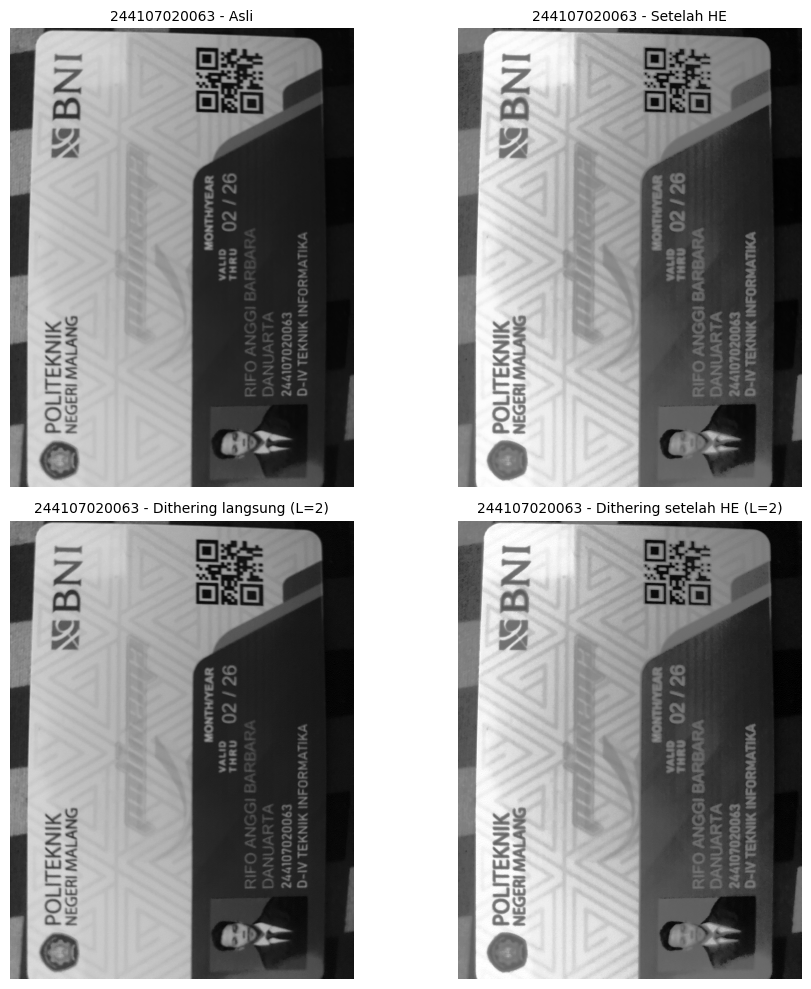

In [41]:
he_ktm1a, dither_setelah_he_ktm1a = he_lalu_dither(ktm1a_gray, L=PARAM['L'])
dither_langsung_ktm1a = floyd_steinberg(ktm1a_gray, L=PARAM['L'])

show_images(
    [ktm1a_gray, he_ktm1a, dither_langsung_ktm1a, dither_setelah_he_ktm1a],
    [NIM + ' - Asli', NIM + ' - Setelah HE',
     NIM + f" - Dithering langsung (L={PARAM['L']})", NIM + f" - Dithering setelah HE (L={PARAM['L']})"],
    cols=2
)


**Jawaban Langkah 2:** Dithering yang dikerjakan **setelah histogram equalization** umumnya menghasilkan teks pada KTM yang **lebih terbaca** dibanding dithering langsung tanpa ekualisasi, karena:
- Ekualisasi lebih dulu meregangkan kontras sehingga tepi antara tulisan (gelap/terang) dan latar kartu menjadi lebih tajam **sebelum** dikuantisasi ke `L` level oleh dithering.
- Tanpa ekualisasi, jika citra asli memang kontrasnya rendah (mis. `KTM1a.jpg` yang diambil di ruangan gelap), sebagian besar piksel berkumpul pada rentang intensitas sempit — saat dikuantisasi langsung ke `L` level yang sedikit (`L = 2` berarti hanya hitam-putih), banyak detail tulisan yang justru **hilang total** karena seluruh area gelap dipetakan ke level yang sama.
- Dengan ekualisasi lebih dulu, distribusi intensitas sudah lebih menyebar ke seluruh rentang 0-255, sehingga proses kuantisasi `L` level pada dithering punya "bahan" kontras yang lebih kaya untuk dipetakan menjadi pola titik hitam-putih yang membentuk tepi tulisan dengan lebih jelas.
- [ Isi: konfirmasi pengamatan ini berdasarkan hasil visual `KTM1a.jpg` Anda sendiri di atas — apakah nama dan NIM benar-benar lebih terbaca pada gambar "Dithering setelah HE" dibanding "Dithering langsung"? ]